# Assignment 2 — Notebook 3/5: Mini-Batch Gradient Descent
**Course:** Neural Networks and Learning Machines — Binary Logistic Regression with five optimizers

## The real-world problem: early detection of diabetes
Type 2 diabetes often stays undiagnosed for years. A simple model that flags patients at high risk from
routine measurements (glucose, BMI, blood pressure, age, …) can send them for a proper test earlier.

**Dataset (Kaggle):** [pima-indians-diabetes.csv](https://www.kaggle.com/datasets/kumargh/pimaindiansdiabetescsv)
(CC0) — 768 female patients of Pima Indian heritage, aged 21+, collected by the US National Institute of
Diabetes and Digestive and Kidney Diseases.
**Target:** `Outcome` — **1 = diabetic (positive class)**, 0 = not diabetic.

**Goal of this notebook:** train with **Mini-Batch GD** (batches of 32 patients) and compare different batch sizes.

All five notebooks use **the same data, the same split, the same preprocessing, the same initial weights
and 100 epochs**, so their results can be compared directly:

| # | Notebook | Optimizer | Batch size |
|---|---|---|---|
| 1 | `01_gradient_descent.ipynb` | Gradient Descent (GD) | all training samples |
| 2 | `02_sgd.ipynb` | Stochastic Gradient Descent (SGD) | 1 |
| 3 | `03_mini_batch_gd.ipynb` | Mini-Batch Gradient Descent | 32 |
| 4 | `04_rmsprop.ipynb` | RMSProp (chosen instead of AdaGrad) | 32 |
| 5 | `05_adam_and_comparison.ipynb` | Adam + final comparison of all five | 32 |

Everything (model, loss, gradients, optimizers, metrics) is written **from scratch with NumPy**.
No prebuilt classifier is used for training.

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 42
EPOCHS = 100
np.random.seed(RANDOM_SEED)
plt.rcParams["figure.dpi"] = 110
COLORS = {"GD": "#1f4e9c", "SGD": "#d62728", "Mini-Batch GD": "#2ca02c", "RMSProp": "#9467bd", "Adam": "#ff7f0e"}

## 1. Data loading and preprocessing
The code below is the project file `data_preprocessing.py`. It:
1. finds the Kaggle CSV (on Kaggle or in the local `data/` folder) — the file has **no header row**, so we name the columns;
2. treats impossible zeros (Glucose, BloodPressure, SkinThickness, Insulin, BMI = 0) as **missing values**;
3. splits **stratified 60 / 20 / 20** (train / validation / test) with seed 42;
4. fills missing values with the **median of the training set**;
5. standardises with `StandardScaler` **fitted on the training set only** (no data leakage).

In [2]:
"""Data loading and preprocessing for Assignment 2.

Real-world problem: early detection of diabetes.
Dataset (Kaggle): "pima-indians-diabetes.csv"
    https://www.kaggle.com/datasets/kumargh/pimaindiansdiabetescsv   (CC0 licence)
    Originally from the National Institute of Diabetes and Digestive and Kidney
    Diseases (NIDDK); 768 female patients of Pima Indian heritage, aged 21+.

Positive class convention (used everywhere in the project):
    1 = diabetic   <- the class we want to detect
    0 = not diabetic
"""
import glob
import os
from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_SEED = 42
CLASS_NAMES = {0: "not diabetic", 1: "diabetic"}
TARGET = "Outcome"
FEATURES = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
            "BMI", "DiabetesPedigreeFunction", "Age"]
# A value of 0 is physically impossible for these measurements -> it means "not measured".
ZERO_MEANS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]


@dataclass
class DataSplits:
    X_train: np.ndarray
    X_val: np.ndarray
    X_test: np.ndarray
    y_train: np.ndarray
    y_val: np.ndarray
    y_test: np.ndarray
    feature_names: list
    medians: pd.Series
    scaler: StandardScaler


def find_csv():
    """Locate the Kaggle CSV on Kaggle (/kaggle/input) or locally (data/ or ../data/)."""
    here = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
    candidates = (glob.glob("/kaggle/input/**/pima-indians-diabetes*.csv", recursive=True)
                  + glob.glob("data/pima-indians-diabetes*.csv")
                  + glob.glob("../data/pima-indians-diabetes*.csv")
                  + glob.glob(os.path.join(here, "data", "pima-indians-diabetes*.csv")))
    if not candidates:
        raise FileNotFoundError("pima-indians-diabetes.csv not found - put it in the data/ folder")
    return candidates[0]


def load_dataset(path=None):
    """Read the CSV (it has no header row) and give the columns their names."""
    path = path or find_csv()
    df = pd.read_csv(path, header=None, names=FEATURES + [TARGET])
    return df[FEATURES], df[TARGET].astype(int)


def describe_dataset(X: pd.DataFrame, y: pd.Series) -> dict:
    """Facts used in the report: shape, class balance, missing values (NaN and hidden zeros)."""
    counts = y.value_counts().sort_index()
    info = {
        "n_samples": X.shape[0], "n_features": X.shape[1],
        "n_not_diabetic": int(counts.get(0, 0)), "n_diabetic": int(counts.get(1, 0)),
        "diabetic_ratio": float(y.mean()), "nan_values": int(X.isna().sum().sum()),
        "duplicate_rows": int(pd.concat([X, y], axis=1).duplicated().sum()),
    }
    for col in ZERO_MEANS_MISSING:
        info[f"zeros_{col}"] = int((X[col] == 0).sum())
    return info


def replace_impossible_zeros(X: pd.DataFrame) -> pd.DataFrame:
    """Glucose = 0 or BMI = 0 cannot be real, so turn those zeros into NaN (missing)."""
    X = X.copy()
    X[ZERO_MEANS_MISSING] = X[ZERO_MEANS_MISSING].replace(0, np.nan)
    return X


def split_and_scale(X: pd.DataFrame, y: pd.Series, seed: int = RANDOM_SEED,
                    val_size: float = 0.20, test_size: float = 0.20) -> DataSplits:
    """Stratified 60 / 20 / 20 split, then median imputation and StandardScaler
    learned from the TRAINING set only (no data leakage)."""
    X = replace_impossible_zeros(X)
    X_tmp, X_test, y_tmp, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=seed)
    rel_val = val_size / (1.0 - test_size)          # 0.20 / 0.80 = 0.25 of the remainder
    X_train, X_val, y_train, y_val = train_test_split(
        X_tmp, y_tmp, test_size=rel_val, stratify=y_tmp, random_state=seed)

    medians = X_train.median()                       # learned on train only
    X_train, X_val, X_test = (d.fillna(medians) for d in (X_train, X_val, X_test))

    scaler = StandardScaler().fit(X_train)           # learned on train only
    return DataSplits(
        X_train=scaler.transform(X_train), X_val=scaler.transform(X_val),
        X_test=scaler.transform(X_test),
        y_train=y_train.to_numpy(dtype=float), y_val=y_val.to_numpy(dtype=float),
        y_test=y_test.to_numpy(dtype=float),
        feature_names=list(X.columns), medians=medians, scaler=scaler)

In [3]:
X, y = load_dataset()
print("Reading:", find_csv())
print("shape:", X.shape, "| target counts:", y.value_counts().sort_index().to_dict())
pd.concat([X, y], axis=1).head()

Reading: ../data/pima-indians-diabetes.csv
shape: (768, 8) | target counts: {0: 500, 1: 268}


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Data quality: missing values, duplicates, class balance
There are no `NaN` cells, but some measurements are **0**, which is impossible for a living patient (glucose, blood pressure, BMI…). They are missing values in disguise.

NaN values: 0 | duplicate rows: 0
               impossible zeros  percent
Glucose                       5      0.7
BloodPressure                35      4.6
SkinThickness               227     29.6
Insulin                     374     48.7
BMI                          11      1.4


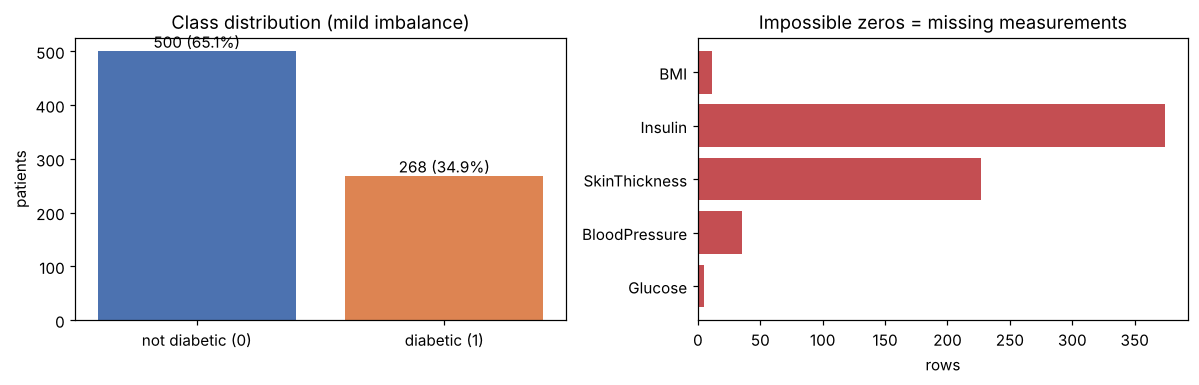

In [4]:
info = describe_dataset(X, y)
print(f"NaN values: {info['nan_values']} | duplicate rows: {info['duplicate_rows']}")
zeros = pd.Series({c: info['zeros_' + c] for c in ZERO_MEANS_MISSING}, name="impossible zeros")
print(zeros.to_frame().assign(percent=lambda d: (100 * d.iloc[:, 0] / len(X)).round(1)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
counts = y.value_counts().sort_index()
ax[0].bar(["not diabetic (0)", "diabetic (1)"], counts.values, color=["#4c72b0", "#dd8452"])
for i, v in enumerate(counts.values): ax[0].text(i, v, f"{v} ({100*v/len(y):.1f}%)", ha="center", va="bottom")
ax[0].set_title("Class distribution (mild imbalance)"); ax[0].set_ylabel("patients")
ax[1].barh(zeros.index, zeros.values, color="#c44e52")
ax[1].set_title("Impossible zeros = missing measurements"); ax[1].set_xlabel("rows")
plt.tight_layout(); plt.show()

### Stratified split, median imputation and scaling (fitted on train only)

In [5]:
splits = split_and_scale(X, y)
for part in ["train", "val", "test"]:
    yy = getattr(splits, f"y_{part}")
    print(f"{part:5s}: X shape {getattr(splits, f'X_{part}').shape} | diabetic {int(yy.sum())} ({yy.mean():.3f})")
print("\ntraining medians used to fill missing values:")
print(splits.medians.round(2).to_dict())
print("\nafter scaling, train mean ≈ 0 and std ≈ 1:",
      splits.X_train.mean(0).round(3).tolist()[:3], splits.X_train.std(0).round(3).tolist()[:3])

train: X shape (460, 8) | diabetic 160 (0.348)
val  : X shape (154, 8) | diabetic 54 (0.351)
test : X shape (154, 8) | diabetic 54 (0.351)

training medians used to fill missing values:
{'Pregnancies': 3.0, 'Glucose': 117.0, 'BloodPressure': 72.0, 'SkinThickness': 30.0, 'Insulin': 125.0, 'BMI': 32.4, 'DiabetesPedigreeFunction': 0.39, 'Age': 29.0}

after scaling, train mean ≈ 0 and std ≈ 1: [0.0, 0.0, 0.0] [1.0, 1.0, 1.0]


## 2. Logistic Regression from scratch (`logistic_regression.py`)
$$z = Xw + b,\qquad p = \sigma(z) = \frac{1}{1+e^{-z}},\qquad \hat y = \begin{cases}1 & p \ge 0.5\\0 & p<0.5\end{cases}$$
**Binary Cross-Entropy:** $\;L = -\frac1m\sum\big[y\log p + (1-y)\log(1-p)\big]$, computed in the stable form
$\max(z,0) - zy + \log(1+e^{-|z|})$.

**Gradients:** $\;\dfrac{\partial L}{\partial w} = \dfrac1m X^T(p-y),\qquad \dfrac{\partial L}{\partial b} = \dfrac1m\sum(p-y)$

In [6]:
"""Binary Logistic Regression implemented from scratch with NumPy.

    z      = X w + b                      (linear part)
    p      = sigmoid(z) = 1 / (1 + e^-z)  (probability of class 1)
    loss   = -mean( y log p + (1 - y) log(1 - p) )   (Binary Cross-Entropy)
    dL/dw  = X^T (p - y) / m
    dL/db  = mean(p - y)
"""
import numpy as np


def sigmoid(z):
    """Numerically stable sigmoid.

    For z >= 0 use 1 / (1 + e^-z); for z < 0 use e^z / (1 + e^z).
    Neither branch ever computes e^(large positive number), so no overflow.
    """
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


def bce_from_logits(z, y):
    """Binary Cross-Entropy computed directly from the logits z (stable form).

    -[y log s(z) + (1-y) log(1-s(z))] = max(z, 0) - z*y + log(1 + e^-|z|)
    This never evaluates log(0), even when |z| is huge.
    """
    z = np.asarray(z, dtype=float)
    y = np.asarray(y, dtype=float)
    return float(np.mean(np.maximum(z, 0) - z * y + np.log1p(np.exp(-np.abs(z)))))


def bce_from_probs(p, y, eps=1e-12):
    """Binary Cross-Entropy from probabilities (clipped to avoid log(0))."""
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    y = np.asarray(y, dtype=float)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


class LogisticRegressionScratch:
    """Parameters: weight vector w (n_features,) and scalar bias b."""

    def __init__(self, n_features, init_seed=0, init_scale=0.01):
        rng = np.random.default_rng(init_seed)
        self.w = rng.normal(0.0, init_scale, size=n_features)
        self.b = 0.0

    # ---- copying (so every optimizer starts from identical parameters) ----
    def get_params(self):
        return {"w": self.w.copy(), "b": float(self.b)}

    def set_params(self, params):
        self.w = params["w"].copy()
        self.b = float(params["b"])

    # ---- forward pass ----
    def linear(self, X):
        return X @ self.w + self.b

    def predict_proba(self, X):
        return sigmoid(self.linear(X))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def loss(self, X, y):
        return bce_from_logits(self.linear(X), y)

    # ---- analytical gradients ----
    def gradients(self, X, y):
        """Return (dL/dw, dL/db) of the mean BCE loss on the batch (X, y)."""
        m = X.shape[0]
        error = self.predict_proba(X) - y          # p - y, shape (m,)
        grad_w = X.T @ error / m                   # shape (n_features,)
        grad_b = float(np.mean(error))             # scalar
        return grad_w, grad_b

## 3. Evaluation metrics (`metrics.py`), positive class = diabetic
| Metric | Formula | Question it answers |
|---|---|---|
| Accuracy | (TP+TN)/(TP+TN+FP+FN) | how many predictions are right? |
| Precision | TP/(TP+FP) | when we say "diabetic", how often are we right? |
| Recall | TP/(TP+FN) | of all diabetic patients, how many did we find? |
| F1-Score | 2·P·R/(P+R) | balance of precision and recall |
| Loss | Binary Cross-Entropy | how good are the probabilities? |

`safe_divide` returns 0 when a denominator is 0; `verify_with_sklearn` cross-checks every number with `sklearn.metrics`.

In [7]:
"""Classification metrics implemented manually with NumPy.

Positive class = 1 (diabetic).
"""
import numpy as np



def safe_divide(numerator, denominator):
    """Return numerator / denominator, or 0.0 when the denominator is 0."""
    return float(numerator) / float(denominator) if denominator != 0 else 0.0


def confusion_counts(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return tp, tn, fp, fn


def confusion_matrix_manual(y_true, y_pred):
    """2x2 matrix with rows = actual, columns = predicted, order [0, 1]:
        [[TN, FP],
         [FN, TP]]   (same layout as sklearn.metrics.confusion_matrix)"""
    tp, tn, fp, fn = confusion_counts(y_true, y_pred)
    return np.array([[tn, fp], [fn, tp]])


def accuracy(y_true, y_pred):
    tp, tn, fp, fn = confusion_counts(y_true, y_pred)
    return safe_divide(tp + tn, tp + tn + fp + fn)


def precision(y_true, y_pred):
    tp, _, fp, _ = confusion_counts(y_true, y_pred)
    return safe_divide(tp, tp + fp)


def recall(y_true, y_pred):
    tp, _, _, fn = confusion_counts(y_true, y_pred)
    return safe_divide(tp, tp + fn)


def f1_score(y_true, y_pred):
    p, r = precision(y_true, y_pred), recall(y_true, y_pred)
    return safe_divide(2 * p * r, p + r)


def evaluate(y_true, y_prob, threshold=0.5):
    """All metrics for one model on one dataset."""
    y_pred = (np.asarray(y_prob) >= threshold).astype(int)
    tp, tn, fp, fn = confusion_counts(y_true, y_pred)
    return {
        "Accuracy": accuracy(y_true, y_pred), "Precision": precision(y_true, y_pred),
        "Recall": recall(y_true, y_pred), "F1-Score": f1_score(y_true, y_pred),
        "Loss": bce_from_probs(y_prob, y_true),
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
    }


def verify_with_sklearn(y_true, y_prob, manual, threshold=0.5, tol=1e-9):
    """Cross-check the manual metrics against sklearn.metrics. Returns True/False per metric."""
    from sklearn import metrics as skm
    y_pred = (np.asarray(y_prob) >= threshold).astype(int)
    ref = {
        "Accuracy": skm.accuracy_score(y_true, y_pred),
        "Precision": skm.precision_score(y_true, y_pred, zero_division=0),
        "Recall": skm.recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": skm.f1_score(y_true, y_pred, zero_division=0),
        "Loss": skm.log_loss(y_true, np.clip(y_prob, 1e-12, 1 - 1e-12), labels=[0, 1]),
    }
    cm_ok = np.array_equal(skm.confusion_matrix(y_true, y_pred, labels=[0, 1]),
                           confusion_matrix_manual(y_true, y_pred))
    checks = {k: abs(manual[k] - ref[k]) < 1e-6 if k == "Loss" else abs(manual[k] - ref[k]) < tol
              for k in ref}
    checks["ConfusionMatrix"] = bool(cm_ok)
    return checks

## 4. Shared training loop (`optimizers.py`)
Every epoch the training data is shuffled, cut into batches, and for every batch we compute the gradients
and call `optimizer.step(...)`. We record training loss, validation loss, number of updates and time.

In [8]:
def train(model, optimizer, X_train, y_train, X_val, y_val,
          epochs=100, batch_size=None, shuffle_seed=0, track_updates=False):
    """Generic training loop shared by all five optimizers.

    Records per epoch: training loss, validation loss, cumulative number of
    parameter updates and cumulative wall-clock time (seconds).
    With track_updates=True it also records the training loss after EVERY
    update (used to measure how noisy / stable an optimizer is).
    """
    rng = np.random.default_rng(shuffle_seed)
    m = X_train.shape[0]
    bs = m if batch_size is None else batch_size
    history = {"epoch": [0], "train_loss": [model.loss(X_train, y_train)],
               "val_loss": [model.loss(X_val, y_val)], "updates": [0], "time_s": [0.0]}
    update_loss = [history["train_loss"][0]] if track_updates else None
    updates, elapsed = 0, 0.0
    for epoch in range(1, epochs + 1):
        t0 = time.perf_counter()
        order = rng.permutation(m) if bs < m else np.arange(m)   # shuffle every epoch
        for start in range(0, m, bs):
            idx = order[start:start + bs]
            grad_w, grad_b = model.gradients(X_train[idx], y_train[idx])
            optimizer.step(model, grad_w, grad_b)
            updates += 1
            if track_updates:
                update_loss.append(model.loss(X_train, y_train))
        elapsed += time.perf_counter() - t0
        history["epoch"].append(epoch)
        history["train_loss"].append(model.loss(X_train, y_train))
        history["val_loss"].append(model.loss(X_val, y_val))
        history["updates"].append(updates)
        history["time_s"].append(elapsed)
    if track_updates:
        history["update_loss"] = update_loss
    return history

In [9]:
# helpers used below (identical in all five notebooks)
init_params = LogisticRegressionScratch(splits.X_train.shape[1], init_seed=0).get_params()   # same start for every optimizer

def run(make_opt, batch_size, epochs=EPOCHS):
    model = LogisticRegressionScratch(splits.X_train.shape[1]); model.set_params(init_params)
    hist = train(model, make_opt(), splits.X_train, splits.y_train, splits.X_val, splits.y_val,
                 epochs=epochs, batch_size=batch_size, shuffle_seed=RANDOM_SEED)
    return model, hist

def lr_search(make_opt_lr, batch_size, grid):
    rows = []
    for lr in grid:
        model, hist = run(lambda: make_opt_lr(lr), batch_size)
        v = evaluate(splits.y_val, model.predict_proba(splits.X_val))
        rows.append({"learning_rate": lr, "final_val_loss": hist["val_loss"][-1],
                     "val_accuracy": v["Accuracy"], "val_f1": v["F1-Score"]})
    table = pd.DataFrame(rows)
    best = float(table.sort_values(["final_val_loss", "learning_rate"]).iloc[0]["learning_rate"])
    return table, best

def plot_curves(hist, title, color):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(hist["epoch"], hist["train_loss"], color=color, lw=2, label="training loss")
    ax.plot(hist["epoch"], hist["val_loss"], color=color, lw=2, ls="--", label="validation loss")
    ax.set_xlabel("epoch"); ax.set_ylabel("Binary Cross-Entropy"); ax.set_title(title)
    ax.grid(alpha=.3); ax.legend(); plt.show()

def test_report(model, name):
    prob = model.predict_proba(splits.X_test)
    m = evaluate(splits.y_test, prob)
    ok = verify_with_sklearn(splits.y_test, prob, m)
    cm = confusion_matrix_manual(splits.y_test, (prob >= 0.5).astype(int))
    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{[['TN','FP'],['FN','TP']][i][j]}\n{cm[i, j]}", ha="center", va="center",
                    fontsize=13, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["not diabetic", "diabetic"]); ax.set_yticks([0, 1])
    ax.set_yticklabels(["not diabetic", "diabetic"]); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(f"{name}: confusion matrix (test)"); plt.show()
    print("matches sklearn.metrics:", ok)
    return pd.DataFrame([m], index=[name]).round(4)

## 5. Optimizer 3 — Mini-Batch Gradient Descent
The training data is shuffled and cut into batches $B$ of size $k$; one update per batch:
$$w \leftarrow w - \alpha\,\frac{1}{|B|}X_B^T(p_B-y_B)$$
With 460 patients and $k=32$: $\lceil 460/32\rceil = 15$ updates per epoch (14 full batches + one of 12).
It is the compromise between GD (smooth, few updates) and SGD (many noisy updates).

In [10]:
class GradientDescent:
    """Plain update rule: theta <- theta - lr * gradient.

    Used for GD, SGD and Mini-batch GD (the batch size is set by ``train``).
    """

    def __init__(self, learning_rate=0.1):
        self.learning_rate = learning_rate

    def step(self, model, grad_w, grad_b):
        model.w = model.w - self.learning_rate * grad_w
        model.b = model.b - self.learning_rate * grad_b

## 6. Choosing the learning rate on the VALIDATION set
Grid: `[0.005, 0.01, 0.05, 0.1, 0.5]`. We keep the learning rate with the lowest validation loss after 100 epochs. The test set is not touched here.

chosen learning rate: 0.01


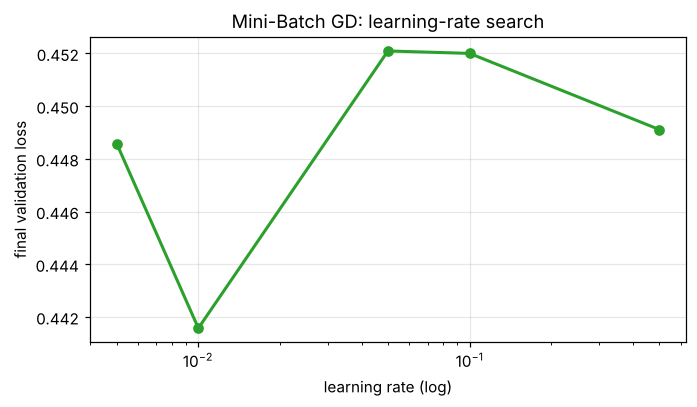

,learning_rate,final_val_loss,val_accuracy,val_f1
0,0.005,0.4486,0.8117,0.7010
1,0.010,0.4416,0.8052,0.6875
2,0.050,0.4521,0.7792,0.6531
3,0.100,0.4520,0.7792,0.6531
4,0.500,0.4491,0.7922,0.6735


In [11]:
search, best_lr = lr_search(lambda lr: GradientDescent(lr), 32, [0.005, 0.01, 0.05, 0.1, 0.5])
print('chosen learning rate:', best_lr)
plt.figure(figsize=(7, 3.6)); plt.semilogx(search.learning_rate, search.final_val_loss, 'o-', color=COLORS['Mini-Batch GD'], lw=2)
plt.xlabel('learning rate (log)'); plt.ylabel('final validation loss'); plt.title('Mini-Batch GD: learning-rate search')
plt.grid(alpha=.3); plt.show()
search.round(4)

## 7. Training Mini-Batch GD with the chosen learning rate

updates per epoch: 15 | total updates: 1500 | training time: 33.7 ms
final training loss 0.4643 | final validation loss 0.4416
weights after training: [ 0.233  0.943 -0.051  0.055  0.044  0.565  0.272  0.159] | bias: -0.734


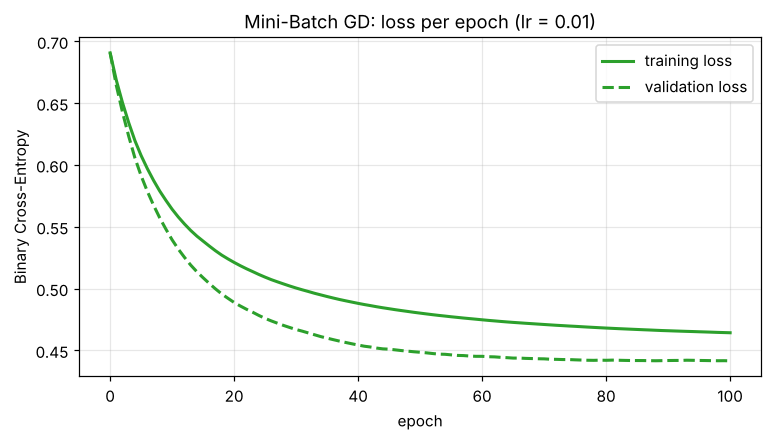

In [12]:
model, hist = run(lambda: (lambda lr: GradientDescent(lr))(best_lr), 32)
print(f"updates per epoch: {hist['updates'][1]} | total updates: {hist['updates'][-1]} | training time: {1000*hist['time_s'][-1]:.1f} ms")
print(f"final training loss {hist['train_loss'][-1]:.4f} | final validation loss {hist['val_loss'][-1]:.4f}")
print('weights after training:', np.round(model.w, 3), '| bias:', round(model.b, 3))
plot_curves(hist, 'Mini-Batch GD: loss per epoch (lr = ' + str(best_lr) + ')', COLORS['Mini-Batch GD'])

## 8. Extra experiment — configurable batch size
Same learning rate, batch sizes 8, 16, 32, 64, 128.

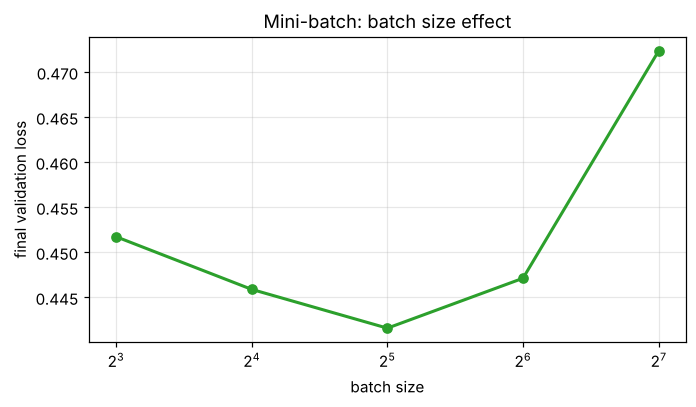

,batch size,updates/epoch,final train loss,final val loss,time (ms)
0,8,58,0.4570,0.4517,106.3823
1,16,29,0.4583,0.4459,78.9520
2,32,15,0.4643,0.4416,30.4265
3,64,8,0.4783,0.4471,17.1206
4,128,4,0.5059,0.4723,10.0936


In [13]:
rows = []
for bs in [8, 16, 32, 64, 128]:
    m_bs, h = run(lambda: GradientDescent(best_lr), bs)
    rows.append({"batch size": bs, "updates/epoch": h["updates"][1], "final train loss": h["train_loss"][-1],
                 "final val loss": h["val_loss"][-1], "time (ms)": 1000 * h["time_s"][-1]})
bs_table = pd.DataFrame(rows)
plt.figure(figsize=(7, 3.6)); plt.plot(bs_table["batch size"], bs_table["final val loss"], "o-", color=COLORS["Mini-Batch GD"], lw=2)
plt.xscale("log", base=2); plt.xlabel("batch size"); plt.ylabel("final validation loss"); plt.title("Mini-batch: batch size effect")
plt.grid(alpha=.3); plt.show()
bs_table.round(4)

## 9. Final evaluation on the untouched TEST set (154 patients)

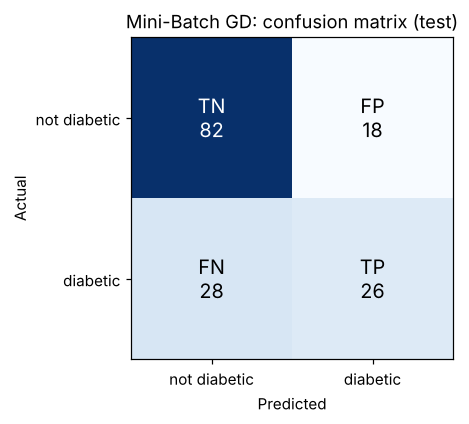

matches sklearn.metrics: {'Accuracy': True, 'Precision': True, 'Recall': True, 'F1-Score': True, 'Loss': True, 'ConfusionMatrix': True}


,Accuracy,Precision,Recall,F1-Score,Loss,TP,TN,FP,FN
Mini-Batch GD,0.7013,0.5909,0.4815,0.5306,0.5104,26,82,18,28


In [14]:
test_report(model, 'Mini-Batch GD')

## Conclusions — Mini-Batch Gradient Descent
* Chosen learning rate: **α = 0.01** with batch size 32 → **15 updates per epoch**.
* Batch-size experiment (same α): small batches (8, 16) make more updates and reach a lower training loss in 100 epochs but take longer; large batches (64, 128) are fast but progress slowly (batch 128: validation loss 0.4723). **Batch 32 gave the lowest validation loss (0.4416).**
* Only 9.6 % of its updates increased the training loss (vs 23 % for SGD) — much smoother than SGD, much faster per epoch than GD.
* Test set: Accuracy 0.7013, Precision 0.5909, Recall 0.4815, F1 0.5306, Loss 0.5104 — the same confusion matrix as SGD (TP 26, TN 82, FP 18, FN 28).